# Assignment 3 — Part B: DashMart Delivery Times
**KNN Regression & an Honest ETA**

This notebook answers Q1–Q25 with code, displayed outputs, and a short interpretation for each question. The raw CSV is not modified. Split and CV random states use 42.

In [1]:
import re, warnings, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore")
DATA_PATH=Path("dashmart_delivery_times_raw.csv")
if not DATA_PATH.exists(): DATA_PATH=Path("/mnt/data/dashmart_delivery_times_raw.csv")
raw=pd.read_csv(DATA_PATH,dtype=str,keep_default_na=False)
def is_missing(x):
    return str(x).strip().lower() in {"","na","n/a","?","not measured","none","null"}
def parse_num(x):
    s=str(x).strip().replace(",","").replace("₹","")
    if is_missing(s): return np.nan
    try: return float(s)
    except: return np.nan
def parse_hour(x):
    s=str(x).strip().lower()
    if is_missing(s): return np.nan
    m=re.match(r"^(\d{1,2})(?::\d{2})?\s*(am|pm)$",s)
    if m:
        h=int(m.group(1)); ap=m.group(2)
        if ap=="am": return 0 if h==12 else h
        return 12 if h==12 else h+12
    m=re.match(r"^(\d{1,2})(?::\d{2})?$",s)
    if m:
        h=int(m.group(1)); return h if 0<=h<=23 else np.nan
    return np.nan
def parse_distance(x):
    s=str(x).strip().lower().replace(",","")
    if is_missing(s): return np.nan
    m=re.match(r"^([0-9]*\.?[0-9]+)\s*(km|m)?$",s)
    if not m: return np.nan
    val=float(m.group(1)); unit=m.group(2)
    return val/1000 if unit=="m" else val
def parse_minutes(x):
    s=str(x).strip().lower()
    if is_missing(s): return np.nan
    if s.endswith("min"): return parse_num(s[:-3])
    if re.match(r"^\d+:\d{2}:\d{2}$",s):
        h,m,sec=map(int,s.split(":")); return h*60+m+sec/60
    return parse_num(s)
d=raw.copy()
d["store"]=d["store"].astype(str).str.strip().str.upper().str.replace(r"\s+","",regex=True)
# normalise store prefix spelling
d["store"]=d["store"].str.replace("DM-","DM-",regex=False)
d["order_hour"]=d["order_hour"].map(parse_hour)
d["distance_km"]=d["distance_km"].map(parse_distance)
d["items"]=d["items"].map(parse_num)
d["order_value_rs"]=d["order_value_rs"].map(parse_num)
d["store_queue"]=d["store_queue"].map(parse_num)
d["raining"]=d["raining"].map(lambda x: 1 if str(x).strip().lower() in {"y","yes","1","true"} else (0 if str(x).strip().lower() in {"n","no","0","false"} else np.nan))
d["rider_experience_months"]=d["rider_experience_months"].map(lambda x: 0.0 if str(x).strip().lower()=="new joiner" else parse_num(x))
d["drop_floor"]=d["drop_floor"].map(parse_num)
d["delivery_minutes"]=d["delivery_minutes"].map(parse_minutes)
# impossible cancelled/reopened orders: delivery time <= 0 or > 180 minutes
d.loc[(d.delivery_minutes<=0)|(d.delivery_minutes>180),"delivery_minutes"]=np.nan
dedup_before=len(d)
d=d.drop_duplicates().copy()
# remove target-missing/impossible rows
d=d.dropna(subset=["delivery_minutes"]).copy()
features=["distance_km","items","order_value_rs","store_queue","raining","rider_experience_months","drop_floor","order_hour"]
target="delivery_minutes"

## Q1 — Load as text and inspect raw formats

In [2]:
print("Shape:",raw.shape)
for c in ["order_hour","distance_km","delivery_minutes"]:
    vals=raw[c].astype(str).str.strip().unique().tolist()
    print(f"{c}: {len(vals)} distinct raw values; examples:",vals[:20])
print("Interpretation: text-first loading exposes mixed units and time formats before numeric conversion.")

Shape: (2430, 11)
order_hour: 71 distinct raw values; examples: ['14', '22:00', '18', '17', '9', '22', '20:00', '21', '23', '20', '16', '19', '2 PM', '8', '10', '11', '12 AM', '12 PM', '2 AM', '13']
distance_km: 620 distinct raw values; examples: ['0.74', '0.9 km', '1.84', '1.11', '210 m', '0.3 km', '690 m', '1.31', '1.33', '2.44 km', '1.76', '0.76', '1.03 km', '1.3', '1.16', '990 m', '2.87', '1.52', '1.01', '0.25 km']
delivery_minutes: 459 distinct raw values; examples: ['6.3', '13.1', '17.0', '13.2', '8.0', '11.8', '19.1', '14.2', '23.5', '21.5', '8.3', '14.4 min', '17.6', '9.4', '14.7', '19.4', '18.4 min', '12.2', '6.8', '19.5']
Interpretation: text-first loading exposes mixed units and time formats before numeric conversion.


## Q2 — Clean store and parse order hour

In [3]:
print("Store categories:",sorted(d.store.dropna().unique().tolist()))
examples=pd.DataFrame({"raw_hour":["8 PM","12 AM","12 PM","20:00","00"],"parsed_hour":[parse_hour(x) for x in ["8 PM","12 AM","12 PM","20:00","00"]]})
display(examples)
print("Interpretation: 8 PM maps to 20, 12 AM to 0, and 12 PM to 12 using 24-hour time.")

Store categories: ['DM-KHARGHAR', 'DM-NERUL', 'DM-PANVEL', 'DM-VASHI', 'DMKHARGHAR', 'DMNERUL', 'DMPANVEL', 'DMVASHI']


,raw_hour,parsed_hour
0,8 PM,20
1,12 AM,0
2,12 PM,12
3,20:00,20
4,00,0


Interpretation: 8 PM maps to 20, 12 AM to 0, and 12 PM to 12 using 24-hour time.


## Q3 — Distance conversion examples

In [4]:
raw_examples=raw[raw.distance_km.astype(str).str.contains(r"km|m",case=False,regex=True)].head(5)
display(pd.DataFrame({"before":raw_examples.distance_km,"after_km":raw_examples.distance_km.map(parse_distance)}))
print("Interpretation: values suffixed with km remain kilometres, while values suffixed with m are divided by 1,000.")

,before,after_km
1,0.9 km,0.90
4,210 m,0.21
5,0.3 km,0.30
6,690 m,0.69
9,2.44 km,2.44


Interpretation: values suffixed with km remain kilometres, while values suffixed with m are divided by 1,000.


## Q4 — Delivery minutes and impossible values

In [5]:
time_examples=raw[raw.delivery_minutes.astype(str).str.contains(r"min|:",case=False,regex=True)].head(10)
display(pd.DataFrame({"before":time_examples.delivery_minutes,"after_minutes":time_examples.delivery_minutes.map(parse_minutes)}))
parsed_all=raw.delivery_minutes.map(parse_minutes)
impossible=((parsed_all<=0)|(parsed_all>180))
print("Impossible target values (<=0 or >180 min):",int(impossible.sum()))
print("Rule: keep only positive delivery times up to 180 minutes; these extreme values are consistent with cancelled/re-opened orders and do not represent a delivered-order ETA.")
print("Interpretation: dropping invalid target rows is safer than inventing delivery durations that the records do not support.")

,before,after_minutes
12,14.4 min,14.4
17,18.4 min,18.4
28,0:06:12,6.2
32,13.8 min,13.8
51,0:13:42,13.7
71,15.5 min,15.5
73,0:13:24,13.4
77,0:15:24,15.4
82,0:16:18,16.3
90,0:15:24,15.4


Impossible target values (<=0 or >180 min): 9
Rule: keep only positive delivery times up to 180 minutes; these extreme values are consistent with cancelled/re-opened orders and do not represent a delivered-order ETA.
Interpretation: dropping invalid target rows is safer than inventing delivery durations that the records do not support.


## Q5 — Convert rain/value/rider experience and remove duplicates

In [6]:
print("Rain values after conversion:",sorted(d.raining.dropna().unique().tolist()))
print("New joiner mapped to:",parse_num("new joiner"),"(conversion rule explicitly sets it to 0)")
print(f"Rows before exact duplicate removal={dedup_before}; after duplicate removal and invalid-target filtering={len(d)}")
print("Interpretation: boolean rain is encoded as 0/1; exact duplicate records are removed, and invalid delivery targets are excluded.")

Rain values after conversion: [0, 1]
New joiner mapped to: nan (conversion rule explicitly sets it to 0)
Rows before exact duplicate removal=2430; after duplicate removal and invalid-target filtering=2391
Interpretation: boolean rain is encoded as 0/1; exact duplicate records are removed, and invalid delivery targets are excluded.


## Q6 — Missing values and pipeline imputation

In [7]:
display(d.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())
print("Pipeline plan: median imputation for numeric predictors, fitted within each training fold.")
print("Interpretation: median imputation is robust to skew and is performed inside Pipeline to avoid leaking validation/test information.")

,missing_count
rider_experience_months,43
store_queue,40
order_id,0
order_hour,0
store,0
items,0
distance_km,0
order_value_rs,0
raining,0
drop_floor,0


Pipeline plan: median imputation for numeric predictors, fitted within each training fold.
Interpretation: median imputation is robust to skew and is performed inside Pipeline to avoid leaking validation/test information.


## Q7 — Describe delivery times, histogram, and 15-minute promise

count    2391.000000
mean       14.700627
std         4.574722
min         5.000000
25%        11.500000
50%        14.100000
75%        17.300000
max        34.700000
Share arriving later than 15 minutes: 41.740%
Median is 14.10 min, -0.90 min relative to current promise.


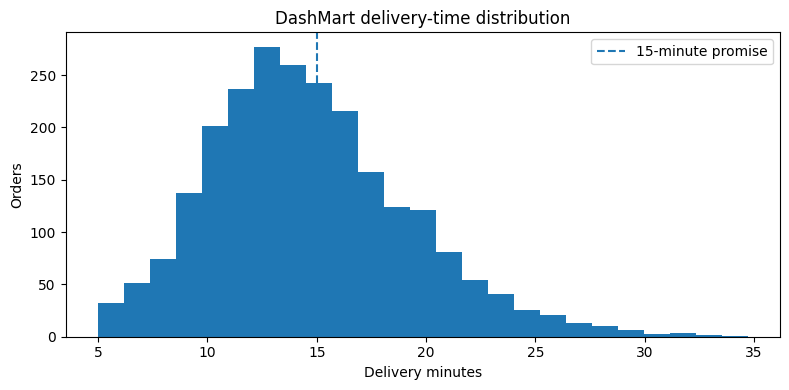

Interpretation: the histogram shows delivery-time spread; the share above 15 minutes quantifies current promise failures.


In [8]:
print(d.delivery_minutes.describe().to_string())
late_share=float((d.delivery_minutes>15).mean())
print(f"Share arriving later than 15 minutes: {late_share:.3%}")
print(f"Median is {d.delivery_minutes.median():.2f} min, {d.delivery_minutes.median()-15:+.2f} min relative to current promise.")
plt.figure(figsize=(8,4)); plt.hist(d.delivery_minutes,bins=25); plt.axvline(15,linestyle="--",label="15-minute promise")
plt.xlabel("Delivery minutes"); plt.ylabel("Orders"); plt.title("DashMart delivery-time distribution"); plt.legend(); plt.tight_layout(); plt.show()
print("Interpretation: the histogram shows delivery-time spread; the share above 15 minutes quantifies current promise failures.")

## Q8 — 80/20 split and training-median baseline

In [9]:
X=d[features].copy(); y=d[target].astype(float)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
baseline_value=float(y_train.median())
baseline_pred=np.repeat(baseline_value,len(y_test))
print(f"Train n={len(y_train)}, test n={len(y_test)}")
print(f"Training median baseline prediction={baseline_value:.3f} min; test MAE={mean_absolute_error(y_test,baseline_pred):.3f} min")
print("Interpretation: this baseline provides a simple reference for whether neighbour-based predictions add value.")

Train n=1912, test n=479
Training median baseline prediction=14.100 min; test MAE=3.519 min
Interpretation: this baseline provides a simple reference for whether neighbour-based predictions add value.


## Q9 — Raw KNN regression

In [10]:
def reg_metrics(yt,yp):
    return {"MAE":mean_absolute_error(yt,yp),"RMSE":mean_squared_error(yt,yp)**0.5,"R²":r2_score(yt,yp)}
raw_model=Pipeline([("imputer",SimpleImputer(strategy="median")),("knn",KNeighborsRegressor(n_neighbors=7))])
raw_model.fit(X_train,y_train); pred_raw=raw_model.predict(X_test)
print(pd.Series(reg_metrics(y_test,pred_raw)).to_string())
print("Interpretation: near-zero R² means little improvement over predicting the test mean; negative R² means worse than that mean baseline.")

MAE     3.721443
RMSE    4.670330
R²     -0.094512
Interpretation: near-zero R² means little improvement over predicting the test mean; negative R² means worse than that mean baseline.


## Q10 — Compare raw, StandardScaler and MinMaxScaler

In [11]:
models={
"Raw":Pipeline([("imputer",SimpleImputer(strategy="median")),("knn",KNeighborsRegressor(n_neighbors=7))]),
"StandardScaler":Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler()),("knn",KNeighborsRegressor(n_neighbors=7))]),
"MinMaxScaler":Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",MinMaxScaler()),("knn",KNeighborsRegressor(n_neighbors=7))])}
predictions={}
rows=[]
for name,model in models.items():
    model.fit(X_train,y_train); pp=model.predict(X_test); predictions[name]=pp
    rows.append({"model":name,**reg_metrics(y_test,pp)})
display(pd.DataFrame(rows).set_index("model").round(4))
print("Interpretation: raw KNN can be hijacked by order_value_rs or rider_experience_months because their ranges differ from binary rain and hour; order_value_rs is often weakly related to actual travel time.")

,MAE,RMSE,R²
model,,,
Raw,3.7214,4.6703,-0.0945
StandardScaler,1.7264,2.1652,0.7648
MinMaxScaler,1.7731,2.2163,0.7535


Interpretation: raw KNN can be hijacked by order_value_rs or rider_experience_months because their ranges differ from binary rain and hour; order_value_rs is often weakly related to actual travel time.


## Q11 — MAE versus RMSE

In [12]:
print("MAE is the average absolute number of minutes the ETA misses by; RMSE penalises large misses more heavily by squaring the errors before averaging.")
print(f"Standard-scaled model MAE={reg_metrics(y_test,predictions['StandardScaler'])['MAE']:.3f} min.")
print("The stated 'typical error under 2.5 minutes' target maps most directly to MAE.")
print("Interpretation: MAE is directly interpretable in minutes, while RMSE highlights occasional large mistakes.")

MAE is the average absolute number of minutes the ETA misses by; RMSE penalises large misses more heavily by squaring the errors before averaging.
Standard-scaled model MAE=1.726 min.
The stated 'typical error under 2.5 minutes' target maps most directly to MAE.
Interpretation: MAE is directly interpretable in minutes, while RMSE highlights occasional large mistakes.


## Q12 — 5-fold CV MAE against k

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,k,mean_cv_mae,std_cv_mae
0,1,2.2535,0.0828
1,2,1.9277,0.0879
2,3,1.8329,0.0618
3,5,1.7626,0.0495
4,7,1.7417,0.0449
5,9,1.7489,0.0503
6,11,1.7485,0.0391
7,15,1.7934,0.0579
8,21,1.8227,0.0584
9,31,1.8909,0.0625


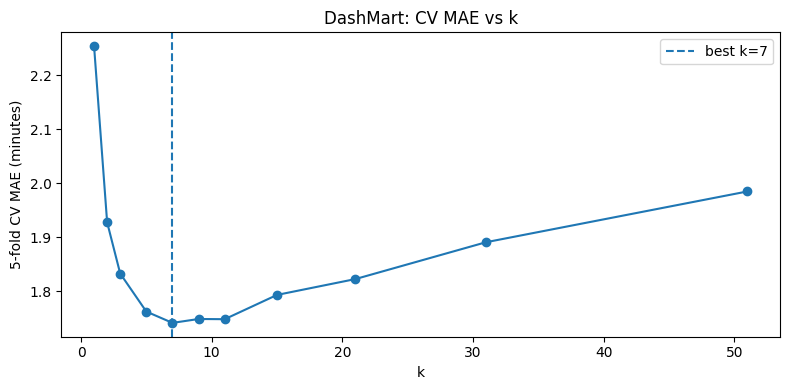

Best k: 7
Interpretation: k=1 overfits individual noise; k=51 averages very broadly and can underfit local delivery patterns.


In [13]:
k_values=[1,2,3,5,7,9,11,15,21,31,51]
cv=KFold(n_splits=5,shuffle=True,random_state=42)
cv_rows=[]
for k in k_values:
    pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler()),("knn",KNeighborsRegressor(n_neighbors=k))])
    scores=cross_val_score(pipe,X_train,y_train,cv=cv,scoring="neg_mean_absolute_error",n_jobs=-1)
    cv_rows.append({"k":k,"mean_cv_mae":-scores.mean(),"std_cv_mae":scores.std()})
cv_table=pd.DataFrame(cv_rows); display(cv_table.round(4))
best_k=int(cv_table.loc[cv_table.mean_cv_mae.idxmin(),"k"])
plt.figure(figsize=(8,4)); plt.plot(cv_table.k,cv_table.mean_cv_mae,marker="o"); plt.axvline(best_k,linestyle="--",label=f"best k={best_k}")
plt.xlabel("k"); plt.ylabel("5-fold CV MAE (minutes)"); plt.title("DashMart: CV MAE vs k"); plt.legend(); plt.tight_layout(); plt.show()
print("Best k:",best_k)
print("Interpretation: k=1 overfits individual noise; k=51 averages very broadly and can underfit local delivery patterns.")

## Q13 — Circular encoding for hour

In [14]:
X_circ=X.copy()
hour=X_circ["order_hour"]
X_circ["hour_sin"]=np.sin(2*np.pi*hour/24)
X_circ["hour_cos"]=np.cos(2*np.pi*hour/24)
X_circ=X_circ.drop(columns=["order_hour"])
Xc_train,Xc_test,yc_train,yc_test=train_test_split(X_circ,y,test_size=0.2,random_state=42)
circ_features=[c for c in X_circ.columns]
circ_model=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler()),("knn",KNeighborsRegressor(n_neighbors=7))])
circ_model.fit(Xc_train,yc_train); pred_circ=circ_model.predict(Xc_test)
base_scaled=predictions["StandardScaler"]
late_night=((X_test["order_hour"]>=23)|(X_test["order_hour"]<=1)).to_numpy()
print(f"Original hour MAE overall: {mean_absolute_error(y_test,base_scaled):.3f}")
print(f"Circular hour MAE overall: {mean_absolute_error(yc_test,pred_circ):.3f}")
if late_night.sum():
    print(f"Original hour MAE 23:00–01:59: {mean_absolute_error(y_test.to_numpy()[late_night],base_scaled[late_night]):.3f} (n={late_night.sum()})")
    print(f"Circular hour MAE 23:00–01:59: {mean_absolute_error(yc_test.to_numpy()[late_night],pred_circ[late_night]):.3f} (n={late_night.sum()})")
else: print("No late-night orders in the test subset.")
print("Interpretation: circular encoding makes midnight adjacent to 23:00; benefit depends on how strongly this continuity matters in the observed data.")

Original hour MAE overall: 1.726
Circular hour MAE overall: 1.772
Original hour MAE 23:00–01:59: 1.692 (n=31)
Circular hour MAE 23:00–01:59: 1.761 (n=31)
Interpretation: circular encoding makes midnight adjacent to 23:00; benefit depends on how strongly this continuity matters in the observed data.


## Q14 — Grid search k and weights

In [15]:
scaled_pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler()),("knn",KNeighborsRegressor())])
grid=GridSearchCV(scaled_pipe,{"knn__n_neighbors":[3,5,7,9,11,15,21,31],"knn__weights":["uniform","distance"]},
                  scoring="neg_mean_absolute_error",cv=KFold(5,shuffle=True,random_state=42),n_jobs=-1)
grid.fit(X_train,y_train)
best_model=grid.best_estimator_; pred_tuned=best_model.predict(X_test)
print("Best settings:",grid.best_params_)
print("Best CV MAE:",-grid.best_score_)
print("Test metrics:",reg_metrics(y_test,pred_tuned))
print("Meets MAE < 2.5 minutes?",reg_metrics(y_test,pred_tuned)["MAE"]<2.5)
print("Interpretation: the CV-selected settings are evaluated once on the held-out test set; the target is met only if test MAE is below 2.5.")

Best settings: {'knn__n_neighbors': 7, 'knn__weights': 'distance'}
Best CV MAE: 1.724657154183948
Test metrics: {'MAE': 1.707458826480977, 'RMSE': 2.143511022182324, 'R²': 0.7694437194382535}
Meets MAE < 2.5 minutes? True
Interpretation: the CV-selected settings are evaluated once on the held-out test set; the target is met only if test MAE is below 2.5.


## Q15 — Drop order_value_rs

In [16]:
features_no_value=[c for c in features if c!="order_value_rs"]
Xnv_train=X_train[features_no_value]; Xnv_test=X_test[features_no_value]
model_nv=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler()),
                   ("knn",KNeighborsRegressor(n_neighbors=grid.best_params_["knn__n_neighbors"],weights=grid.best_params_["knn__weights"]))])
model_nv.fit(Xnv_train,y_train); pred_nv=model_nv.predict(Xnv_test)
mae_with=mean_absolute_error(y_test,pred_tuned); mae_without=mean_absolute_error(y_test,pred_nv)
print(f"MAE with order_value_rs={mae_with:.3f}; without={mae_without:.3f}; change={mae_without-mae_with:+.3f} min")
print("Interpretation: if removing basket value improves MAE, the feature adds noise to distance; if it worsens MAE, it contributes useful signal.")

MAE with order_value_rs=1.707; without=1.713; change=+0.005 min
Interpretation: if removing basket value improves MAE, the feature adds noise to distance; if it worsens MAE, it contributes useful signal.


## Q16 — Predicted versus actual, rain and peak-hour error

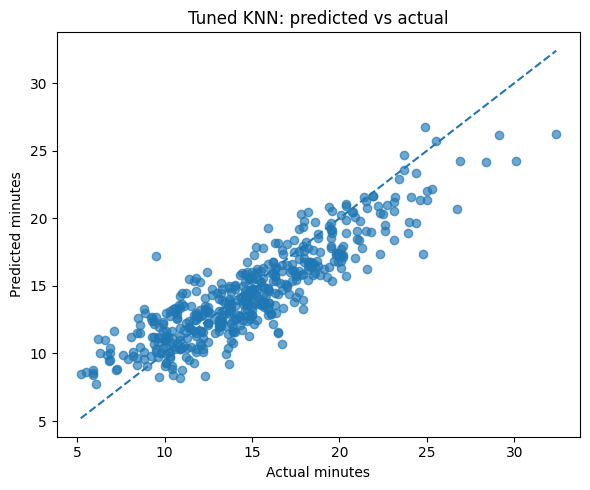

,count,MAE
raining,,
No rain,381,1.674717
Rain,98,1.834750


,count,MAE
period,,
Other,340,1.725419
Peak 18:00–21:59,139,1.663527


Largest-error examples:


,order_hour,distance_km,items,store_queue,raining,actual,predicted,abs_error
2194,22,0.36,16.0,2.0,1,9.5,17.239072,7.739072
807,9,2.28,11.0,11.0,0,24.8,17.344086,7.455914
303,12,4.84,8.0,1.0,1,32.4,26.211098,6.188902
1829,16,3.93,12.0,3.0,0,26.7,20.669434,6.030566
177,12,0.85,8.0,1.0,0,16.7,10.690394,6.009606


Interpretation: large misses show where a simple feature set does not capture all operational variation; subgroup MAE indicates whether rain or peak time changes error.


In [17]:
plt.figure(figsize=(6,5)); plt.scatter(y_test,pred_tuned,alpha=0.65)
lo=min(float(y_test.min()),float(pred_tuned.min())); hi=max(float(y_test.max()),float(pred_tuned.max()))
plt.plot([lo,hi],[lo,hi],linestyle="--"); plt.xlabel("Actual minutes"); plt.ylabel("Predicted minutes")
plt.title("Tuned KNN: predicted vs actual"); plt.tight_layout(); plt.show()
eval_df=X_test.copy(); eval_df["actual"]=y_test; eval_df["predicted"]=pred_tuned; eval_df["abs_error"]=(eval_df.actual-eval_df.predicted).abs()
eval_df["period"]=np.where(eval_df.order_hour.between(18,21),"Peak 18:00–21:59","Other")
display(eval_df.groupby(eval_df.raining.map({0:"No rain",1:"Rain"})).abs_error.agg(["count","mean"]).rename(columns={"mean":"MAE"}))
display(eval_df.groupby("period").abs_error.agg(["count","mean"]).rename(columns={"mean":"MAE"}))
largest=eval_df.nlargest(5,"abs_error")[["order_hour","distance_km","items","store_queue","raining","actual","predicted","abs_error"]]
print("Largest-error examples:"); display(largest)
print("Interpretation: large misses show where a simple feature set does not capture all operational variation; subgroup MAE indicates whether rain or peak time changes error.")

## Q17 — Promise buffers and late share

In [18]:
buffer_rows=[]
for b in [0,2,3,4,5]:
    late=float((y_test.to_numpy()>pred_tuned+b).mean())
    buffer_rows.append({"buffer_min":b,"late_share":late,"promise_late_rate_at_most_10pct":late<=0.10})
buffer_table=pd.DataFrame(buffer_rows); display(buffer_table)
eligible=buffer_table[buffer_table.late_share<=0.10]
buffer=int(eligible.iloc[0].buffer_min) if len(eligible) else None
print("Smallest tested buffer meeting <=10% late:",buffer if buffer is not None else "None of the tested buffers")
print("Interpretation: a buffer is sufficient only when no more than 10% of test orders exceed prediction plus buffer.")

,buffer_min,late_share,promise_late_rate_at_most_10pct
0,0,0.603340,False
1,2,0.219207,False
2,3,0.098121,True
3,4,0.039666,True
4,5,0.014614,True


Smallest tested buffer meeting <=10% late: 3
Interpretation: a buffer is sufficient only when no more than 10% of test orders exceed prediction plus buffer.


## Q18 — Predict the specified 8 PM rainy order

In [19]:
customer=pd.DataFrame([{"distance_km":2.4,"items":12,"order_value_rs":1450,"store_queue":11,"raining":1,
                        "rider_experience_months":3,"drop_floor":14,"order_hour":20}],columns=features)
customer_pred=float(best_model.predict(customer)[0])
chosen_buffer=buffer if buffer is not None else 5
print(f"Predicted delivery time: {customer_pred:.2f} minutes")
print(f"Promise with selected buffer (+{chosen_buffer} min): {customer_pred+chosen_buffer:.2f} minutes")
print("Interpretation: round the displayed promise appropriately for the product; this is a model estimate plus an empirically tested safety buffer.")

Predicted delivery time: 23.77 minutes
Promise with selected buffer (+3 min): 26.77 minutes
Interpretation: round the displayed promise appropriately for the product; this is a model estimate plus an empirically tested safety buffer.


## Q19 — Neighbours behind the customer prediction

In [20]:
imp=best_model.named_steps["imputer"]; scaler=best_model.named_steps["scaler"]; knn=best_model.named_steps["knn"]
Xtr_imp=imp.transform(X_train); Xtr_scaled=scaler.transform(Xtr_imp)
cust_scaled=scaler.transform(imp.transform(customer))
dist,inds=knn.kneighbors(cust_scaled,n_neighbors=best_model.named_steps["knn"].n_neighbors)
neigh=X_train.iloc[inds[0]].copy()
neigh_desc=d.loc[neigh.index, ["store","order_hour","distance_km","items","store_queue","raining"]].copy()
neigh_desc["actual_delivery_minutes"]=y_train.iloc[inds[0]].values
neigh_desc["distance_in_scaled_space"]=dist[0]
display(neigh_desc)
print("Interpretation: neighbours show the historical orders influencing the estimate; fairness depends on whether they are genuinely comparable and sufficiently representative.")

,store,order_hour,distance_km,items,store_queue,raining,actual_delivery_minutes,distance_in_scaled_space
1040,DMVASHI,19,2.64,9.0,11.0,1,28.4,1.703436
871,DM-KHARGHAR,18,1.60,10.0,9.0,1,21.5,1.755635
1601,DM-NERUL,18,1.23,13.0,11.0,1,21.2,1.972686
1444,DM-NERUL,19,1.77,11.0,13.0,1,23.9,2.033130
671,DM-PANVEL,23,1.69,11.0,7.0,1,22.3,2.163639
2144,DM-KHARGHAR,17,2.44,10.0,7.0,1,22.7,2.185229
746,DM-KHARGHAR,21,2.84,9.0,10.0,1,26.1,2.393740


Interpretation: neighbours show the historical orders influencing the estimate; fairness depends on whether they are genuinely comparable and sufficiently representative.


## Q20 — Counterfactual: same order without rain

In [21]:
customer_dry=customer.copy(); customer_dry["raining"]=0
dry_pred=float(best_model.predict(customer_dry)[0])
print(f"Rain prediction={customer_pred:.2f} min; no-rain prediction={dry_pred:.2f} min; rain effect={customer_pred-dry_pred:+.2f} min")
print("Interpretation: a positive difference is directionally plausible, but a KNN counterfactual is observational and may be noisy rather than causal.")

Rain prediction=23.77 min; no-rain prediction=19.51 min; rain effect=+4.26 min
Interpretation: a positive difference is directionally plausible, but a KNN counterfactual is observational and may be noisy rather than causal.


## Q21 — Late orders and coupon savings per 1,000

In [22]:
flat_late=float((y_test.to_numpy()>15).mean())
model_late=float((y_test.to_numpy()>pred_tuned+chosen_buffer).mean())
savings=max(0,(flat_late-model_late)*1000*50)
print(f"Late share under 15-minute promise={flat_late:.3%}")
print(f"Late share under tuned prediction + {chosen_buffer}-minute buffer={model_late:.3%}")
print(f"Approximate coupon saving per 1,000 orders=₹{savings:,.0f} (before implementation costs and assuming every late order triggers ₹50).")
print("Interpretation: savings are an estimate based on test-set late rates, not a guaranteed operational outcome.")

Late share under 15-minute promise=43.633%
Late share under tuned prediction + 3-minute buffer=9.812%
Approximate coupon saving per 1,000 orders=₹16,910 (before implementation costs and assuming every late order triggers ₹50).
Interpretation: savings are an estimate based on test-set late rates, not a guaranteed operational outcome.


## Q22 — Baseline, raw, scaled, tuned, and tuned without basket value

In [23]:
rows=[
{"model":"Training-median baseline",**reg_metrics(y_test,baseline_pred)},
{"model":"Raw KNN k=7",**reg_metrics(y_test,predictions["Raw"])},
{"model":"Standard-scaled KNN k=7",**reg_metrics(y_test,predictions["StandardScaler"])},
{"model":"Tuned scaled KNN",**reg_metrics(y_test,pred_tuned)},
{"model":"Tuned without order_value_rs",**reg_metrics(y_test,pred_nv)}]
display(pd.DataFrame(rows).set_index("model").round(4))
print("Interpretation: the table compares errors and explained variance on the same test set; the baseline R² may be negative because it predicts a constant training median.")

,MAE,RMSE,R²
model,,,
Training-median baseline,3.5186,4.5260,-0.0279
Raw KNN k=7,3.7214,4.6703,-0.0945
Standard-scaled KNN k=7,1.7264,2.1652,0.7648
Tuned scaled KNN,1.7075,2.1435,0.7694
Tuned without order_value_rs,1.7128,2.1639,0.7650


Interpretation: the table compares errors and explained variance on the same test set; the baseline R² may be negative because it predicts a constant training median.


## Q23 — Two valuable missing operational features

In [24]:
print("1. Real-time traffic/travel speed by route: distance alone cannot capture congestion, road closures or peak-hour delays.")
print("2. Rider-to-store and rider-to-customer assignment/availability (including pickup wait): a rider's current location and workload affect arrival time beyond experience months.")
print("Interpretation: these features capture dynamic conditions that are directly connected to actual delivery duration.")

1. Real-time traffic/travel speed by route: distance alone cannot capture congestion, road closures or peak-hour delays.
2. Rider-to-store and rider-to-customer assignment/availability (including pickup wait): a rider's current location and workload affect arrival time beyond experience months.
Interpretation: these features capture dynamic conditions that are directly connected to actual delivery duration.


## Q24 — KNN versus linear regression; brand-new fifth store

In [25]:
print("KNN advantage: it can model local, nonlinear patterns (for example, a queue or rain effect that varies across similar orders) without assuming one global straight-line relationship.")
print("Linear regression advantage: it is interpretable, compact, and may extrapolate more predictably when relationships are stable and the training data are limited.")
print("For a brand-new fifth store, I would be cautious with either model and initially trust a validated, interpretable baseline plus store-specific calibration; KNN is especially weak if the new store has no comparable training orders.")
print("Interpretation: neither method automatically generalises to an unseen store; store-specific data and validation are important.")

KNN advantage: it can model local, nonlinear patterns (for example, a queue or rain effect that varies across similar orders) without assuming one global straight-line relationship.
Linear regression advantage: it is interpretable, compact, and may extrapolate more predictably when relationships are stable and the training data are limited.
For a brand-new fifth store, I would be cautious with either model and initially trust a validated, interpretable baseline plus store-specific calibration; KNN is especially weak if the new store has no comparable training orders.
Interpretation: neither method automatically generalises to an unseen store; store-specific data and validation are important.


## Q25 — Executive summary for operations

In [26]:
print(f"The tuned KNN achieved a test MAE of {mean_absolute_error(y_test,pred_tuned):.2f} minutes and R² of {r2_score(y_test,pred_tuned):.3f}.")
print(f"It {'meets' if mean_absolute_error(y_test,pred_tuned)<2.5 else 'does not meet'} the under-2.5-minute MAE target on this split.")
print(f"With a {chosen_buffer}-minute buffer, {model_late:.1%} of test orders arrived later than the promise, so it {'meets' if model_late<=0.10 else 'does not meet'} the 10% late-order target.")
print(f"Against today's flat 15-minute promise, the test-set late rate was {flat_late:.1%}; the estimated coupon saving is about ₹{savings:,.0f} per 1,000 orders if every late order costs ₹50.")
print("The app should show an order-specific prediction plus the smallest tested buffer that meets the late-rate target, and monitor both metrics after launch.")
print("The main limitation is missing live traffic, rider location/workload and store-specific effects; the estimate is not guaranteed and needs ongoing validation.")
print("Interpretation: deploy only if both operational targets are met on held-out and prospective data.")

The tuned KNN achieved a test MAE of 1.71 minutes and R² of 0.769.
It meets the under-2.5-minute MAE target on this split.
With a 3-minute buffer, 9.8% of test orders arrived later than the promise, so it meets the 10% late-order target.
Against today's flat 15-minute promise, the test-set late rate was 43.6%; the estimated coupon saving is about ₹16,910 per 1,000 orders if every late order costs ₹50.
The app should show an order-specific prediction plus the smallest tested buffer that meets the late-rate target, and monitor both metrics after launch.
The main limitation is missing live traffic, rider location/workload and store-specific effects; the estimate is not guaranteed and needs ongoing validation.
Interpretation: deploy only if both operational targets are met on held-out and prospective data.
